# Подготовка данных: движение товаров в количестве

**Цель:** Загрузить Excel с многоуровневыми заголовками, преобразовать данные о движении товаров из широкого формата в длинный, очистить итоговые строки и сформировать помесячный датасет по SKU.

**Вход:** `Движение.xlsx` (не приложен из-за конфиденциальности).

**Основные шаги:** обработка MultiIndex, melt, парсинг дат, фильтрация по категориям.

**Навыки:** pandas, очистка данных, преобразование wide-to-long.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_excel('Движение.xlsx', header=[0, 1, 2])  # Читаем с многоуровневыми заголовками
df

Артикул                                       Номенклатура  \
      Unnamed: 0_level_1                                 Unnamed: 1_level_1   
      Unnamed: 0_level_2                                 Unnamed: 1_level_2   
0            0Т-00042714                10 300 500 H EVRA (269Вт) ПОД ЗАКАЗ   
1            0Т-00039061      10 500 1000 H  Royal Thermo (820Вт) ПОД ЗАКАЗ   
2            0Т-00042733               10 500 1000 H EVRA (835Вт) ПОД ЗАКАЗ   
3            0Т-00045841      10 500 1100 H  Royal Thermo (902Вт) ПОД ЗАКАЗ   
4            0Т-00041474      10 500 1200 H  Royal Thermo (984Вт) ПОД ЗАКАЗ   
...                  ...                                                ...   
15441        0Т-00032264  яяяяяяяяяяяя11 600х1200 CV Purmo (1539 вт 90/7...   
15442        0Т-00031084             яяяяяяяяяяяяОтвод 110/30 внут Политрон   
15443        0Т-00006458  яяяяяяяяяяяяяяяяяМанометр ТМ-510Р.05 16 кгс/см...   
15444        0Т-00031089  яяяяяяяяяяяяяяяяяОтвод 110/90 с вых. 50 прям. ...   
15445              Итого                                                NaN   

                Ед. изм.    Январь 2021 г.                           \
      Unnamed: 2_level_1 Начальный остаток                   Приход   
      Unnamed: 2_level_2        Количество Себестоимость Количество   
0                     шт              0.00          0.00          0   
1                     шт              0.00          0.00          0   
2                     шт              0.00          0.00          0   
3                     шт              0.00          0.00          0   
4                     шт              0.00          0.00          0   
...                  ...               ...           ...        ...   
15441                 шт              3.00      12231.63          0   
15442                 шт             82.00       2458.55          0   
15443                 шт              1.00          1.00          0   
15444                 шт             37.00       2645.37          0   
15445                NaN         393203.55   39012050.21     318692   

                                                               ...  \
                        Расход               Конечный остаток  ...   
      Себестоимость Количество Себестоимость       Количество  ...   
0              0.00          0          0.00             0.00  ...   
1              0.00          0          0.00             0.00  ...   
2              0.00          0          0.00             0.00  ...   
3              0.00          0          0.00             0.00  ...   
4              0.00          0          0.00             0.00  ...   
...             ...        ...           ...              ...  ...   
15441          0.00          0          0.00             3.00  ...   
15442          0.00         20        599.64            62.00  ...   
15443          0.00          0          0.00             1.00  ...   
15444          0.00         13        929.45            24.00  ...   
15445   25579536.11     203906   22686667.29        508118.55  ...   

          Март 2025 г.                           Итого                \
      Конечный остаток               Начальный остаток                 
            Количество Себестоимость        Количество Себестоимость   
0                 0.00           0.0              0.00          0.00   
1                 0.00           0.0              0.00          0.00   
2                 0.00           0.0              0.00          0.00   
3                 0.00           0.0              0.00          0.00   
4                 0.00           0.0              0.00          0.00   
...                ...           ...               ...           ...   
15441             0.00           0.0              3.00      12231.63   
15442             0.00           0.0             82.00       2458.55   
15443             0.00           0.0              1.00          1.00   
15444             0.00           0.0             37.00       2645.37  

In [3]:
# Удаляем последнюю строку с итогом
df = df.drop(df.tail(1).index)
# Удаляем столбцы, где первый уровень заголовков содержит "Итого"
df = df.loc[:, df.columns.get_level_values(0) != "Итого"]

In [4]:
# создаем df только с количеством
#df_amount = df.loc[:, df.columns.get_level_values(2) != "Себестоимость"] проблема с Апрелем 2022 года
#df_amount = df.loc[:, df.columns.get_level_values(2) == "Количество"] некорректно

df_amount = df.loc[:, 
    (df.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df.columns.get_level_values(2) == "Количество")
]

In [5]:
df_amount.columns.tolist()

[('Артикул', 'Unnamed: 0_level_1', 'Unnamed: 0_level_2'),
 ('Номенклатура', 'Unnamed: 1_level_1', 'Unnamed: 1_level_2'),
 ('Ед. изм.', 'Unnamed: 2_level_1', 'Unnamed: 2_level_2'),
 ('Январь 2021 г.', 'Начальный остаток', 'Количество'),
 ('Январь 2021 г.', 'Приход', 'Количество'),
 ('Январь 2021 г.', 'Расход', 'Количество'),
 ('Январь 2021 г.', 'Конечный остаток', 'Количество'),
 ('Февраль 2021 г.', 'Начальный остаток', 'Количество'),
 ('Февраль 2021 г.', 'Приход', 'Количество'),
 ('Февраль 2021 г.', 'Расход', 'Количество'),
 ('Февраль 2021 г.', 'Конечный остаток', 'Количество'),
 ('Март 2021 г.', 'Начальный остаток', 'Количество'),
 ('Март 2021 г.', 'Приход', 'Количество'),
 ('Март 2021 г.', 'Расход', 'Количество'),
 ('Март 2021 г.', 'Конечный остаток', 'Количество'),
 ('Апрель 2021 г.', 'Начальный остаток', 'Количество'),
 ('Апрель 2021 г.', 'Приход', 'Количество'),
 ('Апрель 2021 г.', 'Расход', 'Количество'),
 ('Апрель 2021 г.', 'Конечный остаток', 'Количество'),
 ('Май 2021 г.', 'На

In [6]:
df_1 = df_amount.loc[:, 
    (df_amount.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df_amount.columns.get_level_values(1) == "Начальный остаток")
]

df_2 = df_amount.loc[:, 
    (df_amount.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df_amount.columns.get_level_values(1) == "Приход")
]

df_3 = df_amount.loc[:, 
    (df_amount.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df_amount.columns.get_level_values(1) == "Расход")
]

df_4 = df_amount.loc[:, 
    (df_amount.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    (df_amount.columns.get_level_values(1) == "Конечный остаток")
]

In [7]:
# df_1
df_1.columns = df_1.columns.droplevel(1)
df_1.columns = df_1.columns.droplevel(1)

# df_2
df_2.columns = df_2.columns.droplevel(1)
df_2.columns = df_2.columns.droplevel(1)

# df_3
df_3.columns = df_3.columns.droplevel(1)
df_3.columns = df_3.columns.droplevel(1)

# df_4
df_4.columns = df_4.columns.droplevel(1)
df_4.columns = df_4.columns.droplevel(1)

In [8]:
df_1

,Артикул,Номенклатура,Ед. изм.,Январь 2021 г.,Февраль 2021 г.,Март 2021 г.,Апрель 2021 г.,Май 2021 г.,Июнь 2021 г.,Июль 2021 г.,...,Июнь 2024 г.,Июль 2024 г.,Август 2024 г.,Сентябрь 2024 г.,Октябрь 2024 г.,Ноябрь 2024 г.,Декабрь 2024 г.,Январь 2025 г.,Февраль 2025 г.,Март 2025 г.
0,0Т-00042714,10 300 500 H EVRA (269Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0Т-00039061,10 500 1000 H Royal Thermo (820Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0Т-00042733,10 500 1000 H EVRA (835Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0Т-00045841,10 500 1100 H Royal Thermo (902Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0Т-00041474,10 500 1200 H Royal Thermo (984Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15440,00001197,яяяяяяяяяяХомут 50 для канал серый пластик КОН...,шт,271.0,271.0,263.0,253.0,60.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15441,0Т-00032264,яяяяяяяяяяяя11 600х1200 CV Purmo (1539 вт 90/7...,шт,3.0,3.0,3.0,3.0,3.0,3.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15442,0Т-00031084,яяяяяяяяяяяяОтвод 110/30 внут Политрон,шт,82.0,62.0,46.0,23.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15443,0Т-00006458,яяяяяяяяяяяяяяяяяМанометр ТМ-510Р.05 16 кгс/см...,шт,1.0,1.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
df_1_long = df_1.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name='Дата', value_name='Начальный остаток')
df_2_long = df_2.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name='Дата', value_name='Приход')
df_3_long = df_3.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name='Дата', value_name='Расход')
df_4_long = df_4.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name='Дата', value_name='Конечный остаток')

In [10]:
df_1_long

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный остаток
0,0Т-00042714,10 300 500 H EVRA (269Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
1,0Т-00039061,10 500 1000 H Royal Thermo (820Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
2,0Т-00042733,10 500 1000 H EVRA (835Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
3,0Т-00045841,10 500 1100 H Royal Thermo (902Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
4,0Т-00041474,10 500 1200 H Royal Thermo (984Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
...,...,...,...,...,...
787690,00001197,яяяяяяяяяяХомут 50 для канал серый пластик КОН...,шт,Март 2025 г.,0.0
787691,0Т-00032264,яяяяяяяяяяяя11 600х1200 CV Purmo (1539 вт 90/7...,шт,Март 2025 г.,0.0
787692,0Т-00031084,яяяяяяяяяяяяОтвод 110/30 внут Политрон,шт,Март 2025 г.,0.0
787693,0Т-00006458,яяяяяяяяяяяяяяяяяМанометр ТМ-510Р.05 16 кгс/см...,шт,Март 2025 г.,0.0


In [11]:
# Определяем общий столбец для объединения (например, ['Артикул', 'Номенклатура', 'Ед. изм.', 'Дата'])
common_columns = ['Артикул', 'Номенклатура', 'Ед. изм.', 'Дата']

# Объединяем все датасеты по этим столбцам
df_final = df_1_long.merge(df_2_long, on=common_columns, how="outer", suffixes=('', '_2'))\
                    .merge(df_3_long, on=common_columns, how="outer", suffixes=('', '_3'))\
                    .merge(df_4_long, on=common_columns, how="outer", suffixes=('', '_4'))
df_final.head()

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный остаток,Приход,Расход,Конечный остаток
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2021 г.,24.0,56.0,66.0,30.0
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2022 г.,0.0,76.0,76.0,0.0
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2023 г.,0.0,20.0,20.0,0.0
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2024 г.,0.0,40.0,40.0,0.0
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Апрель 2021 г.,88.0,8.0,64.0,32.0


In [12]:
#df_final.isna().sum()
print(df_final.duplicated(subset=common_columns).sum())
print(df_1_long.duplicated(subset=common_columns).sum())

0
0


In [13]:
df_final

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный остаток,Приход,Расход,Конечный остаток
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2021 г.,24.0,56.0,66.0,30.0
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2022 г.,0.0,76.0,76.0,0.0
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2023 г.,0.0,20.0,20.0,0.0
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2024 г.,0.0,40.0,40.0,0.0
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Апрель 2021 г.,88.0,8.0,64.0,32.0
...,...,...,...,...,...,...,...,...
787690,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,Январь 2021 г.,8.0,10.0,3.0,15.0
787691,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,Январь 2022 г.,8.0,0.0,0.0,8.0
787692,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,Январь 2023 г.,7.0,0.0,3.0,4.0
787693,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,Январь 2024 г.,5.0,0.0,0.0,5.0


In [14]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787695 entries, 0 to 787694
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Артикул            787695 non-null  object 
 1   Номенклатура       787695 non-null  object 
 2   Ед. изм.           787695 non-null  object 
 3   Дата               787695 non-null  object 
 4   Начальный остаток  787695 non-null  float64
 5   Приход             787695 non-null  float64
 6   Расход             787695 non-null  float64
 7   Конечный остаток   787695 non-null  float64
dtypes: float64(4), object(4)
memory usage: 48.1+ MB


In [15]:
# Создаём словарь соответствий русских месяцев
months_dict = {
    "Январь": "01", "Февраль": "02", "Март": "03", "Апрель": "04",
    "Май": "05", "Июнь": "06", "Июль": "07", "Август": "08",
    "Сентябрь": "09", "Октябрь": "10", "Ноябрь": "11", "Декабрь": "12"
}

# Удаляем "г." и разбиваем строку на месяц и год
df_final["Дата"] = df_final["Дата"].str.replace(" г.", "", regex=False)
df_final["Месяц"] = df_final["Дата"].str.split(" ").str[0]
df_final["Год"] = df_final["Дата"].str.split(" ").str[1]

# Заменяем названия месяцев на числовой формат
df_final["Месяц"] = df_final["Месяц"].map(months_dict)

# Формируем новую дату в формате YYYY-MM-DD
df_final["Дата"] = pd.to_datetime(df_final["Год"] + "-" + df_final["Месяц"] + "-01")
df_final.drop(columns=["Месяц", "Год"], inplace=True)

In [16]:
df_final.columns = ['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток','Приход', 'Расход', 'Конечный_остаток']

In [17]:
df_final

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,24.0,56.0,66.0,30.0
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.0,76.0,76.0,0.0
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.0,20.0,20.0,0.0
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.0,40.0,40.0,0.0
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,88.0,8.0,64.0,32.0
...,...,...,...,...,...,...,...,...
787690,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2021-01-01,8.0,10.0,3.0,15.0
787691,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2022-01-01,8.0,0.0,0.0,8.0
787692,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2023-01-01,7.0,0.0,3.0,4.0
787693,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-01-01,5.0,0.0,0.0,5.0


### Создание КАТЕГОРИЙ товаров ПОД ЗАКАЗ / СКЛАД / другое

In [ ]:
"""
НЕ ПОСТАВЛЯЕТСЯ
не поставляется
НЕ ПОСТАВЛЯЕМ
НЕ ПОСТВЛСЯЮТСЯ
НЕ ПОСТ

УЦЕНКА
ПО ЗАПРОСУ
РАСПРОДАЖА
ДОПРОДАЕМ
ОБЪЕКТНЫЙ
ЛИКВИДАЦИЯ
ликвидация

СНЯТ С ПРОИЗВОДСТВА
СНЯТ С ПРОИЗВ
СНЯТ С ПРОИЗ
СНЯТ С ПР
СНЯТ
"""

In [232]:
# Функция для присваивания категории
def assign_category(nomenklatura):
    if 'СКЛАД' in nomenklatura:
        return 1
    elif ('ПОД ЗАКАЗ' in nomenklatura or 'ПОД  ЗАКАЗ' in nomenklatura or 
          'ПОД ЗАКА' in nomenklatura or 'ПОД заказ' in nomenklatura or 
          'ПОД ЗАКЗА' in nomenklatura or 'ПОДЗАКАЗ' in nomenklatura or 
          'ПОД ЗАКА' in nomenklatura):
            return 2
    else:
        return 0

df_final['Категория'] = df_final['Номенклатура'].apply(assign_category)

In [233]:
# Извлекаем год из даты
df_final['Год'] = df_final['Дата'].dt.year

In [234]:
df_final.head()

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Категория,Год
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,24.0,56.0,66.0,30.0,2,2021
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.0,76.0,76.0,0.0,2,2022
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.0,20.0,20.0,0.0,2,2023
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.0,40.0,40.0,0.0,2,2024
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,88.0,8.0,64.0,32.0,2,2021


### Датасет только СКЛАД

In [235]:
df_final_only_sklad = df_final[df_final['Категория'] == 1].sort_values(by=["Номенклатура", "Дата"]).reset_index(drop=True)

### График по движению для одного товара

In [236]:
df_final_dash_one_kod = df_final[df_final['Код'] == 'ЦБ-00000057'].sort_values(by='Дата').reset_index(drop=True)
#df_final_dash_one_kod

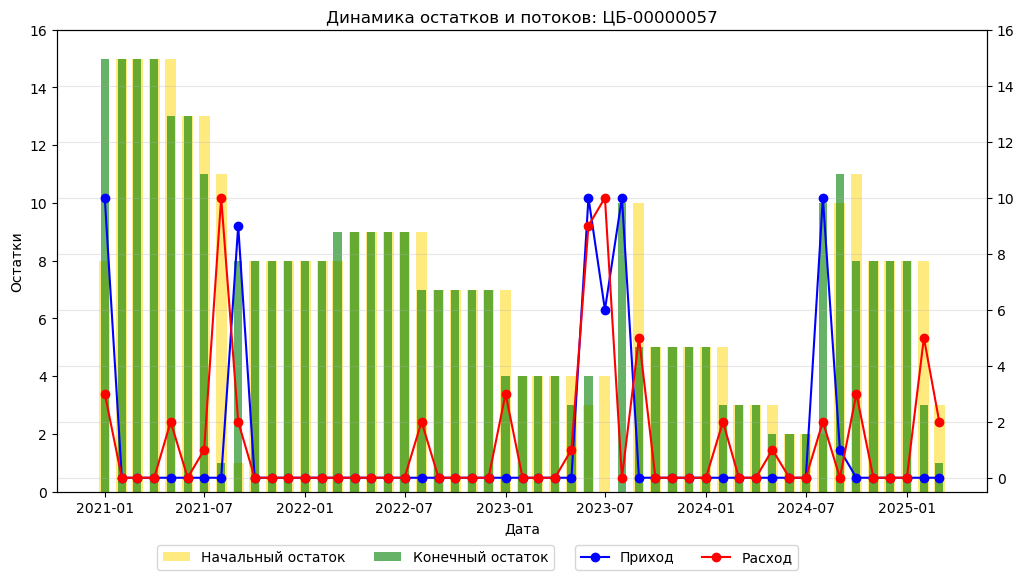

In [237]:
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

# Столбчатая диаграмма (начальный и конечный остатки)
ax1.bar(df_final_dash_one_kod["Дата"], df_final_dash_one_kod["Начальный_остаток"], color='gold', label='Начальный остаток', width=20, alpha=0.5)
ax1.bar(df_final_dash_one_kod["Дата"], df_final_dash_one_kod["Конечный_остаток"], color='green', alpha=0.6, label='Конечный остаток', width=15)

# Линии прихода и расхода
ax2.plot(df_final_dash_one_kod["Дата"], df_final_dash_one_kod["Приход"], marker='o', linestyle='-', color='blue', label='Приход')
ax2.plot(df_final_dash_one_kod["Дата"], df_final_dash_one_kod["Расход"], marker='o', linestyle='-', color='red', label='Расход')

# Определяем максимальные значения для оси Y
max_y1 = max(df_final_dash_one_kod["Начальный_остаток"].max(), df_final_dash_one_kod["Конечный_остаток"].max()) + 1
max_y2 = max(df_final_dash_one_kod["Приход"].max(), df_final_dash_one_kod["Расход"].max()) + 1

# Устанавливаем одинаковый масштаб оси Y
max_y = max(max_y1, max_y2)
ax1.set_ylim(0, max_y)  # Ось Y для столбцов
ax2.set_ylim(-0.5, max_y)  # Ось Y для линейных графиков

# Подписи и легенда
#ax1.set_title(f"Динамика остатков и потоков: {item}")
ax1.set_title("Динамика остатков и потоков: ЦБ-00000057")
ax1.set_xlabel("Дата")
ax1.set_ylabel("Остатки")
#ax2.set_ylabel("Приход/Расход", color='red')


# Легенда для столбцов (основная ось)
ax1.legend(loc="upper left", bbox_to_anchor=(0.1, -0.1), ncol=2)

# Легенда для линий (вторичная ось)
ax2.legend(loc="upper left", bbox_to_anchor=(0.55, -0.1), ncol=2)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

### Цикл для построения графиков

In [238]:
len(df_final_only_sklad["Номенклатура"].unique())

2537

### Расчет СКО датасетов по годам и КОЭФ ВАРИАЦИИ
#### считаем только на основе СКЛАД

In [239]:
df_final_only_sklad.columns

Index(['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток', 'Приход',
       'Расход', 'Конечный_остаток', 'Категория', 'Год'],
      dtype='object')

In [240]:
# Создаем новый датасет с расчетом ско по товарам для каждого кода
df_sko_2021 = df_final_only_sklad[df_final_only_sklad['Год'] == 2021].groupby(['Код', 'Номенклатура', 'Ед_изм'])['Расход'].agg(['sum', 'std', 'mean']).reset_index()
df_sko_2022 = df_final_only_sklad[df_final_only_sklad['Год'] == 2022].groupby(['Код', 'Номенклатура', 'Ед_изм'])['Расход'].agg(['sum', 'std', 'mean']).reset_index()
df_sko_2023 = df_final_only_sklad[df_final_only_sklad['Год'] == 2023].groupby(['Код', 'Номенклатура', 'Ед_изм'])['Расход'].agg(['sum', 'std', 'mean']).reset_index()
df_sko_2024 = df_final_only_sklad[df_final_only_sklad['Год'] == 2024].groupby(['Код', 'Номенклатура', 'Ед_изм'])['Расход'].agg(['sum', 'std', 'mean']).reset_index()
df_sko_all = df_final_only_sklad.groupby(['Код', 'Номенклатура', 'Ед_изм'])['Расход'].agg(['sum', 'std', 'mean']).reset_index()

In [241]:
df_sko_2021['КВ_2021'] = (df_sko_2021['std'] / df_sko_2021['mean']) * 100
df_sko_2022['КВ_2022'] = (df_sko_2022['std'] / df_sko_2022['mean']) * 100
df_sko_2023['КВ_2023'] = (df_sko_2023['std'] / df_sko_2023['mean']) * 100
df_sko_2024['КВ_2024'] = (df_sko_2024['std'] / df_sko_2024['mean']) * 100
df_sko_all['КВ_все'] = (df_sko_all['std'] / df_sko_all['mean']) * 100

In [242]:
df_sko_all.describe()

,sum,std,mean,КВ_все
count,2537.000000,2537.000000,2537.000000,2478.000000
mean,4884.292637,101.620219,95.770444,226.295887
std,27600.665258,462.967051,541.189515,156.576525
min,0.000000,0.000000,0.000000,38.744553
25%,51.000000,2.154248,1.000000,114.498433
50%,266.000000,8.727554,5.215686,181.397586
75%,1669.000000,45.417462,32.725490,278.862693
max,907994.000000,10738.516950,17803.803922,714.142843


In [243]:
df_sko_2021.isna().sum() # заменять на 0 нельзя, так как это не было расхода

Код               0
Номенклатура      0
Ед_изм            0
sum               0
std               0
mean              0
КВ_2021         851
dtype: int64

In [244]:
# Список датасетов и соответствующих годов
df_sko_list = [df_sko_2021, df_sko_2022, df_sko_2023, df_sko_2024, df_sko_all]
years = [2021, 2022, 2023, 2024, 'Все года']
col_names_list = ['КВ_2021', 'КВ_2022', 'КВ_2023', 'КВ_2024', 'КВ_все']

# Создаем DataFrame с пропусками
df_nan_counts = pd.DataFrame({
    'Год': years,
    'Количество товаров без продаж': [df[col].isna().sum() for df, col in zip(df_sko_list, col_names_list)]
})

df_nan_counts

,Год,Количество товаров без продаж
0,2021,851
1,2022,629
2,2023,499
3,2024,215
4,Все года,59


In [245]:
# Указываем только нужные столбцы для объединения
common_columns = ['Код', 'Номенклатура', 'Ед_изм']

# Объединяем все датасеты по этим столбцам
df_sko_final = df_sko_2021[common_columns + ['КВ_2021']]\
    .merge(df_sko_2022[common_columns + ['КВ_2022']], on=common_columns, how="outer")\
    .merge(df_sko_2023[common_columns + ['КВ_2023']], on=common_columns, how="outer")\
    .merge(df_sko_2024[common_columns + ['КВ_2024']], on=common_columns, how="outer")\
    .merge(df_sko_all[common_columns + ['КВ_все']], on=common_columns, how="outer")

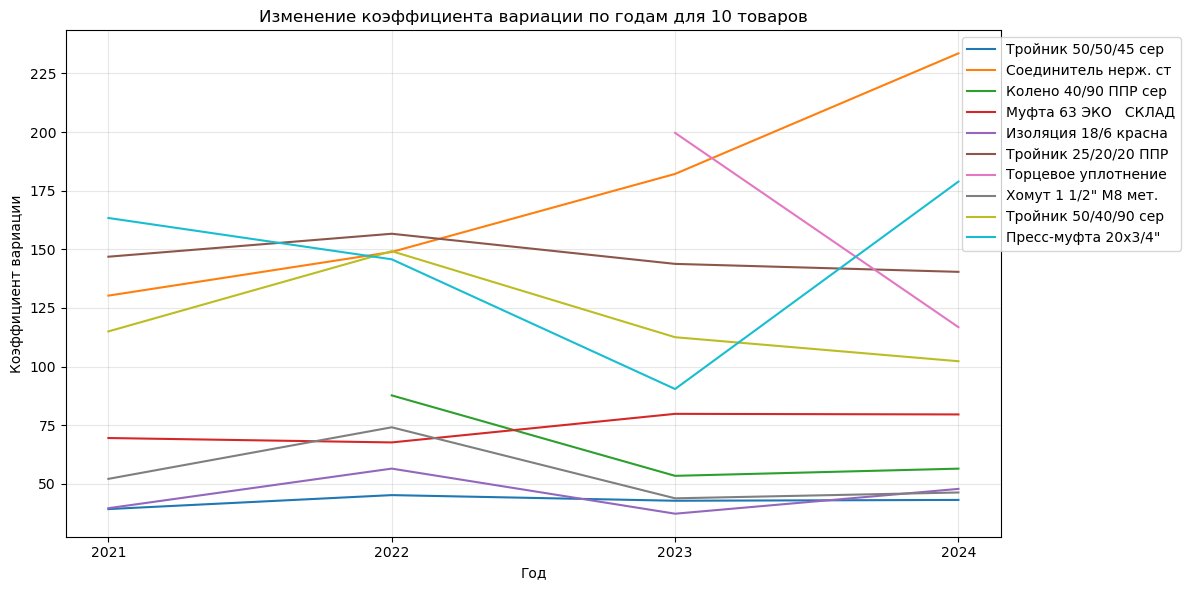

In [246]:
top_10 = df_sko_final.head(10)
top_10_random = df_sko_final.sample(n=10, random_state=34)

# Создаем графики изменения коэффициента вариации по годам для каждого товара
plt.figure(figsize=(12, 6))

for idx, row in top_10_random.iterrows():
    plt.plot(['2021', '2022', '2023', '2024'], [row['КВ_2021'], row['КВ_2022'], row['КВ_2023'], row['КВ_2024']], label=row['Номенклатура'][:20])

plt.title('Изменение коэффициента вариации по годам для 10 товаров')
plt.xlabel('Год')
plt.ylabel('Коэффициент вариации')
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1))
plt.grid(alpha=0.3)
plt.tight_layout()  # Чтобы не было наложений
plt.show()


In [247]:
# Объединяем основной DataFrame с DataFrame коэффициентов по столбцу 'Код'
df_final_only_sklad_sko = df_final_only_sklad.merge(df_sko_final, on=['Код', 'Номенклатура', 'Ед_изм'], how='left')

### Попытка найти ответ на вопрос: а были ли такие товары ПОД ЗАКАЗ, которые продавались в 2024 году в 5-6 месяцах?! не нужно ли их добавить в ассортимент СКЛАД

In [248]:
df_final.head(2)

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Категория,Год
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,24.0,56.0,66.0,30.0,2,2021
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.0,76.0,76.0,0.0,2,2022


In [249]:
df_non_null_sales_in_zakaz_2024 = df_final[(df_final['Категория'] == 2) & (df_final['Год'] == 2024) & (df_final['Расход'] > 0)].copy()

In [250]:
df_non_null_sales_in_zakaz_2024['Месяц'] = df_non_null_sales_in_zakaz_2024['Дата'].dt.month
# Группируем по товару (Код) и считаем количество уникальных месяцев с ненулевыми продажами за 2024 год
# это количество месяцев, в которых у ПОД ЗАКАЗ были ненулевые продажи за 2024
df_months_sales_2024 = df_non_null_sales_in_zakaz_2024.groupby(['Код', 'Номенклатура'])['Месяц'].nunique().reset_index()
df_months_sales_2024.head()

,Код,Номенклатура,Месяц
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,6
1,00-00000176,яРадиатор RC22 500х1400 (2551 вт 90/70/20) Pur...,1
2,00-00000265,Шкаф ШРВ-7 (1300х120-180х648-711) Wester ПО...,1
3,00-00000524,яПереход ПЭ/латунь НР 32*1'' ПОД ЗАКАЗ,1
4,00-00000676,"Комплект т/с вентиль угловой 1/2""+ головка т/с...",2


In [251]:
len(df_months_sales_2024['Номенклатура'].unique())

4086

In [252]:
print('Продавались > 3 из 12 месяцев товаров:', df_months_sales_2024[df_months_sales_2024['Месяц'] > 3]['Месяц'].count())
print('Продавались > 5 из 12 месяцев товаров:', df_months_sales_2024[df_months_sales_2024['Месяц'] > 5]['Месяц'].count())
print('Продавались > 5-8 из 12 месяцев товаров:', df_months_sales_2024[(df_months_sales_2024['Месяц'] > 5) & (df_months_sales_2024['Месяц'] <= 8)]['Месяц'].count())
print('Продавались > 8 из 12 месяцев товаров:', df_months_sales_2024[df_months_sales_2024['Месяц'] > 8]['Месяц'].count())
print('Продавались в 12 из 12 месяцев товаров:', df_months_sales_2024[df_months_sales_2024['Месяц'] == 12]['Месяц'].count())

Продавались > 3 из 12 месяцев товаров: 514
Продавались > 5 из 12 месяцев товаров: 180
Продавались > 5-8 из 12 месяцев товаров: 154
Продавались > 8 из 12 месяцев товаров: 26
Продавались в 12 из 12 месяцев товаров: 1


In [253]:
df_months_sales_2024[(df_months_sales_2024['Месяц'] > 5) & (df_months_sales_2024['Месяц'] <= 8)]['Номенклатура'].unique().tolist()

['Труба 75 Базальт ЭКО  8.4    упак 8 м  кратно 2м ПОД ЗАКАЗ',
 'яОтвод 50/45 Синикон ПОД ЗАКАЗ',
 'яТройник 50/50/45 Синикон ПОД ЗАКАЗ',
 'Кран 1 н/н  бабочка BASE Valtec ПОД ЗАКАЗ /РАСПРОДАЖАупак 6шт',
 'Винтовое 16х3/4" НР соединение обжим Valtec ПОД ЗАКАЗуп 10 шт',
 'Колено 90/90 ЭКО  уп/кор 1/6 шт  ПОД ЗАКАЗ',
 'Муфта 75 ЭКО   уп/кор 1/25 шт  ПОД ЗАКАЗ',
 'Наст к-т д/смес-ля 20х1/2  (универ) упак 10 шт ПОД ЗАКАЗ',
 'Переход 75/63 ВН/НР ЭКО   уп/кор 1/20 шт  ПОД ЗАКАЗ',
 'Переход 90/63 ВН/НР ЭКО     уп/кор 1/20 шт  ПОД ЗАКАЗ',
 'Фланец 90 DN 80     упак 1 шт   ПОД ЗАКАЗ',
 'Бак 50л (10 бар) водоснабж.нож.гориз.с площадкой WАО Wester Line ПОД ЗАКАЗ',
 'Изоляция 48/9 серая дешевая ПОД ЗАКАЗ в наличии',
 'Изоляция 54/20 ПОД ЗАКАЗ упак 30м',
 'яВинтовое 26х3/4" НР соединение обжим Valtec ПОД ЗАКАЗ уп 5 шт',
 'Винтовое 26х1" НР соединение обжим Valtec ПОД ЗАКАЗ уп 5 шт',
 'яПрямой 16х3/4"  внутренний фитинг обжим Valtec  ПОД ЗАКАЗ  уп 10 шт',
 'Пресс-муфта 26х16 Valtec уп 5 шт  ПОД ЗАКА

In [254]:
df_months_sales_2024_more5 = df_months_sales_2024[df_months_sales_2024['Месяц'] > 5]

In [277]:
df_final.columns

Index(['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток', 'Приход',
       'Расход', 'Конечный_остаток', 'Категория', 'Год'],
      dtype='object')

### А сколько товаров вообще продавалось компанией по каждому году? 
по каждому товару сумма расхода за год => должна быть больше 0

In [285]:
df_final_only_sklad[['Код', 'Номенклатура']].nunique()

Код             2537
Номенклатура    2537
dtype: int64

In [286]:
df_final[['Код', 'Номенклатура']].nunique()

Код             15445
Номенклатура    15445
dtype: int64

In [282]:
# Группируем по году и товару (по коду), суммируем расход по каждому товару за год
df_grouped_year = df_final.groupby(['Год', 'Код', 'Номенклатура'])['Расход'].sum().reset_index()
# Фильтруем товары с расходом больше нуля
df_grouped_non_zero = df_grouped_year[df_grouped_year['Расход'] > 0]
result = df_grouped_non_zero.groupby('Год')['Код'].count().reset_index()
result.rename(columns={'Код': 'Количество товаров с расходом > 0 за год'}, inplace=True)
result

,Год,Количество товаров с расходом > 0 за год
0,2021,6851
1,2022,5914
2,2023,6237
3,2024,6916
4,2025,3356


In [287]:
df_grouped_year

,Год,Код,Номенклатура,Расход
0,2021,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,136.0
1,2021,00-00000185,Удлинитель 1/2 15 мм кругл. Valtec.(30) СК...,254.0
2,2021,00-00000186,Удлинитель 1/2 20 мм кругл. Valtec(30)/РОЗ(2) ...,296.0
3,2021,00-00000187,Удлинитель 3/4 20 мм кругл. Valtec (5) СКЛАД...,73.0
4,2021,00-00000188,Удлинитель 1/2 25 мм кругл. Valtec.(20) СК...,101.0
...,...,...,...,...
12680,2025,0Т-00055192,Пер 3/4вн х 1/2нр никел. РТП упак 250/10 шт СК...,46.0
12681,2025,0Т-00055442,"Комплект монтажный Royal Thermo 1”х 3/4"" белый...",14.0
12682,2025,0Т-00055672,Счетчик 1/2 (15) универсальный DUX СВ-15-110 (...,492.0
12683,2025,0Т-00056167,"Насосно-смесительный узел ,т/с головкой, 1""ВР ...",1.0


In [283]:
# Группируем по году и товару (по коду), суммируем расход по каждому товару за год
df_grouped_year = df_final_only_sklad.groupby(['Год', 'Код', 'Номенклатура'])['Расход'].sum().reset_index()
# Фильтруем товары с расходом больше нуля
df_grouped_non_zero = df_grouped_year[df_grouped_year['Расход'] > 0]
result_sklad = df_grouped_non_zero.groupby('Год')['Код'].count().reset_index()
result_sklad.rename(columns={'Код': 'Количество товаров с расходом > 0 за год'}, inplace=True)
result_sklad

,Год,Количество товаров с расходом > 0 за год
0,2021,1686
1,2022,1908
2,2023,2038
3,2024,2322
4,2025,1854


### Сколько товаров в общей массе перестали продавать / продавали весь период / начали продавать недавно

In [ ]:
# Шаг 1: Группируем данные по году и коду товара, чтобы увидеть, в какие годы был расход
df_grouped = df.groupby(['Код', 'Год'])['Расход'].sum().reset_index()

# Шаг 2: Определяем товары, которые продавались в каждом году
sold_in_all_years = df_grouped.groupby('Код').filter(lambda x: len(x) == len(df['Год'].unique()) and (x['Расход'] > 0).all())

# Шаг 3: Определяем товары, которые начали продаваться
# Это товары, которые не имели расхода в какой-то год, но начали его в последующие годы
df_start_selling = df_grouped[df_grouped['Расход'] > 0].groupby('Код').first().reset_index()

# Шаг 4: Определяем товары, которые перестали продаваться
# Это товары, у которых был расход в какой-то год, но в последующие годы расход стал равным нулю
df_stop_selling = df_grouped[df_grouped['Расход'] == 0].groupby('Код').last().reset_index()

# Выводим результаты
print("Товары, которые продавались все время:")
print(sold_in_all_years)

print("\nТовары, которые начали продаваться:")
print(df_start_selling)

print("\nТовары, которые перестали продаваться:")
print(df_stop_selling)


### А какие еще категории есть в данных? И сколько в каждой категории?

In [267]:
print('Количество товаров в категории СКЛАД: ', df_final[df_final['Категория'] == 1]['Номенклатура'].nunique())
print('Количество товаров в категории ПОД ЗАКАЗ: ', df_final[df_final['Категория'] == 2]['Номенклатура'].nunique()) #10175 // 10258 // 10286
#print('Количество товаров в категории ЛИКВИДАЦИЯ: ', df_final[df_final['Категория'] == 3]['Номенклатура'].nunique())
#print('Количество товаров в категории НЕТ ПОСТАВОК: ', df_final[df_final['Категория'] == 4]['Номенклатура'].nunique())
print('Количество товаров в категории ОСТАЛЬНЫЕ: ', df_final[df_final['Категория'] == 0]['Номенклатура'].nunique()) #2179 // 2096 // 1984

Количество товаров в категории СКЛАД:  2537
Количество товаров в категории ПОД ЗАКАЗ:  10286
Количество товаров в категории ОСТАЛЬНЫЕ:  2622


In [256]:
"""
УЦЕНКА
ПО ЗАПРОСУ
РАСПРОДАЖА
ДОПРОДАЕМ
ОБЪЕКТНЫЙ
СНЯТ С ПРОИЗВОДСТВА
СНЯТ С ПРОИЗВ
СНЯТ С ПРОИЗ
СНЯТ С ПР
СНЯТ
"""

'\nУЦЕНКА\nПО ЗАПРОСУ\nРАСПРОДАЖА\nДОПРОДАЕМ\nОБЪЕКТНЫЙ\nСНЯТ С ПРОИЗВОДСТВА\nСНЯТ С ПРОИЗВ\nСНЯТ С ПРОИЗ\nСНЯТ С ПР\nСНЯТ\n'